# Arctic soil-column sensitivity analysis: tutorial
This notebook reproduces the config-8 analysis from the **cached outputs** in `examples/data` (no ATS needed). It calls the `arctic_sa` package, so every step is also available as a CLI command (see the README).

**Workflow.** (1) Morris screening ranks 23 uncertain parameters on 240 cheap runs. (2) A Latin hypercube samples the 17 retained parameters 200 times. (3) A Gaussian-process emulator learns the model from those runs. (4) Sobol indices say which parameters drive the fit. (5) History matching asks which parameter values are still plausible and lists the best compromises, which are then verified with full model runs.

In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from arctic_sa import load_config, observations
from arctic_sa import morris, match, outputs
from arctic_sa.parameters import NAMES, LHS_PARAMETERS
cfg = load_config("../examples/example.yaml"); observations.load(cfg)
D = lambda n: pd.read_csv(os.path.join(cfg.output_dir, "designs", n + ".csv"), index_col=0)
O = lambda n: pd.read_csv(os.path.join(cfg.output_dir, "results", n + "_outputs.csv"), index_col=0)
print(len(observations.FIELD), "field samples (top 35 cm);", len(O("morris")), "Morris and", len(O("lhs")), "Latin-hypercube members with scored outputs")

184 field samples (top 35 cm); 240 Morris and 200 Latin-hypercube members with scored outputs


## 1. Morris screening
Each trajectory moves one parameter at a time; the elementary effect is the change in an output divided by the change in the (unit-scaled) input. **mu\*** is the mean absolute effect (how much the parameter matters); **sigma** shows interactions or non-linearity. Steps that contain members with clamped H$^+$ cells are excluded.

,process,aqueous,rate,overall,keep_for_LHS
R1_k_DOM_aerobic,DOM aerobic respiration,0.520,0.879,0.628,True
R2_k_fermentation,Fermentation,0.438,0.474,0.449,True
logK_FeOH3,Iron cycle,0.293,0.007,0.207,True
R8_K_acetate,Anaerobic acetate oxidation,0.231,0.149,0.206,True
R2_Ki_O2,Fermentation,0.151,0.223,0.173,True
R9_k_Fe2_oxidation,Iron cycle,0.201,0.075,0.163,True
R5_k_CH4_oxidation,H2 / CH4 oxidation,0.173,0.134,0.161,True
R10_k_Fe3_reduction,Iron cycle,0.109,0.155,0.123,True
R8_k_anaerobic_acetate_ox,Anaerobic acetate oxidation,0.114,0.133,0.119,True
CO2cap_threshold,CO2 cap,0.090,0.162,0.112,True


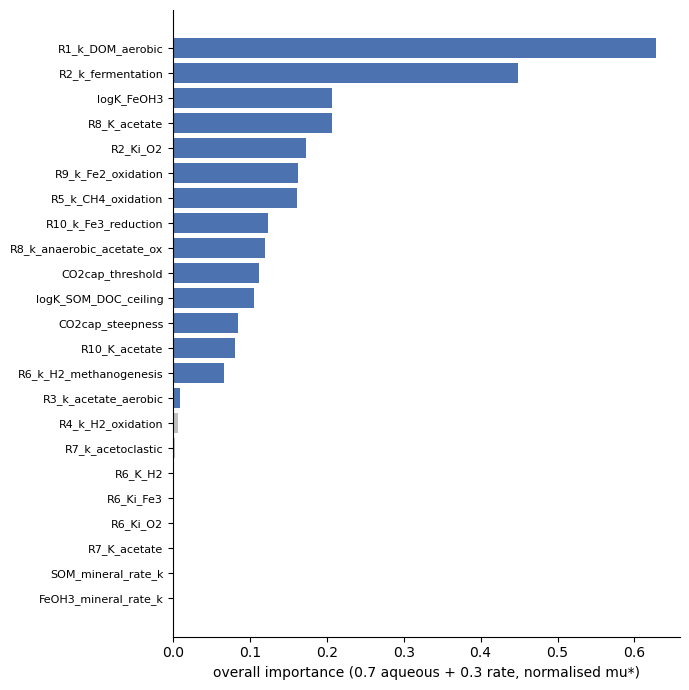

In [2]:
M = morris.run_morris(D("morris"), O("morris"), cfg); R = M["ranking"]
display(R.round(3))
fig, ax = plt.subplots(figsize=(7, 7)); y = np.arange(len(R))[::-1]
ax.barh(y, R["overall"], color=np.where(R["keep_for_LHS"], "#4c72b0", "0.75")); ax.set_yticks(y); ax.set_yticklabels(R.index, fontsize=8)
ax.set_xlabel("overall importance (0.7 aqueous + 0.3 rate, normalised mu*)"); ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

Blue = flagged by the screening rule (normalised mu\* >= 0.1 for any output). Two more parameters (`R6_Ki_Fe3`, `R7_K_acetate`) enter the Latin hypercube because they matter when clamped members are kept, giving 17.

## 2. Emulator (Gaussian process) on the Latin hypercube
One GP per output, fitted on the 200 runs. **Q$^2$** is the 5-fold cross-validated skill: 1 = perfect, 0 = no better than the mean. Expect good skill for rates and concentrations, weak skill for pH and Fe(III) (clamped H$^+$ cells make them noisy).

,CO2(aq)_logratio,CH4(aq)_logratio,DOC_logratio,Fe2+_logratio,Fe(III)_logratio,pH_diff,rate_methanogenesis_logratio,rate_Fe3_reduction_logratio,rate_anaerobic_CO2_logratio,rate_DOM_aerobic_logratio,rate_aerobic_CO2_logratio,aq_score,rate_score,log_clamped
Q2,0.94,0.91,1.0,0.84,0.41,0.27,0.79,0.97,0.82,0.94,0.95,0.71,0.95,0.66


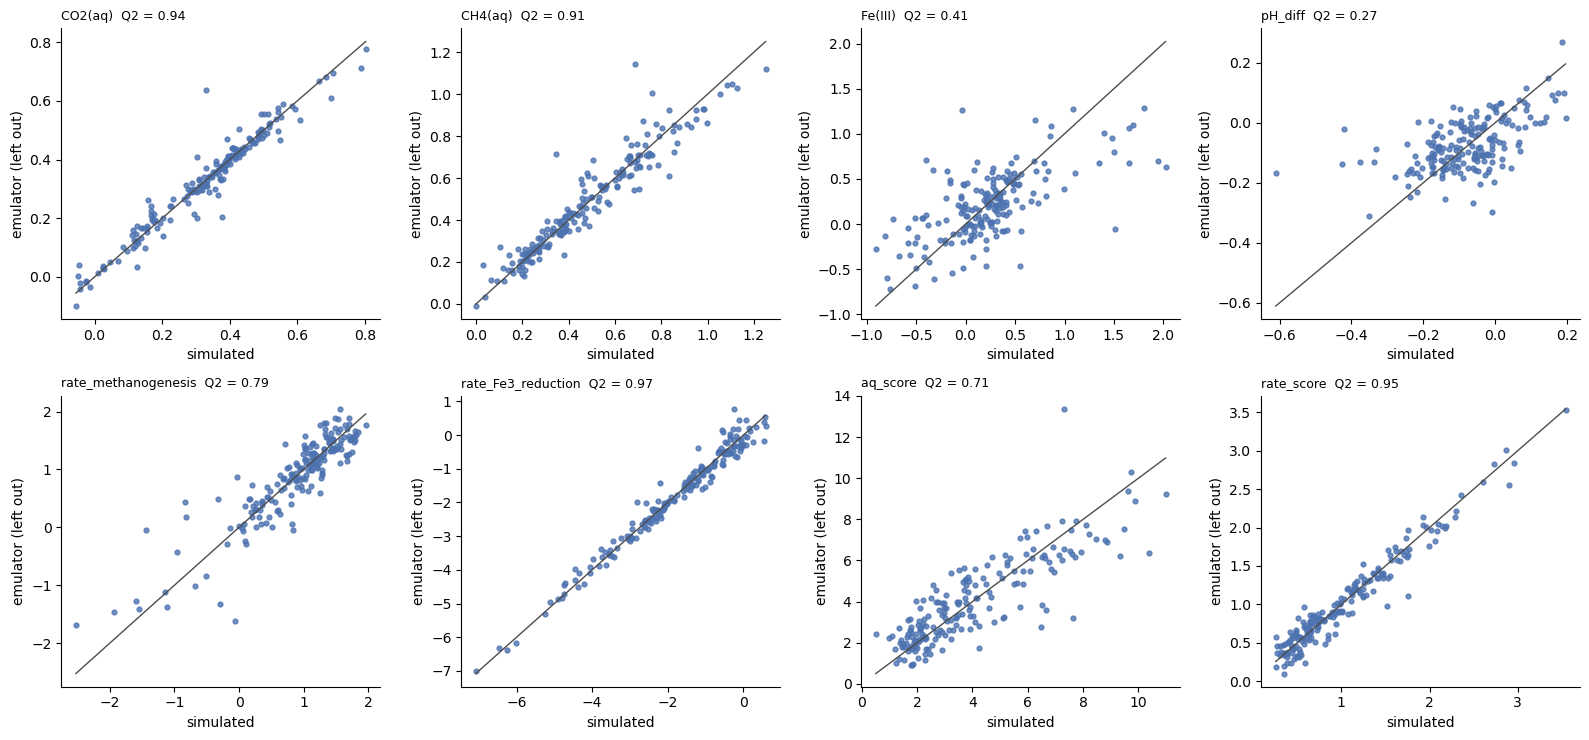

In [3]:
fit = match.fit_lhs(D("lhs"), O("lhs"))
display(fit["q2"].round(2).to_frame().T)
show = ["CO2(aq)_logratio", "CH4(aq)_logratio", "Fe(III)_logratio", "pH_diff", "rate_methanogenesis_logratio", "rate_Fe3_reduction_logratio", "aq_score", "rate_score"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for ax, c in zip(axes.ravel(), show):
    ax.scatter(fit["Y"][c], fit["cv"][c], s=12, color="#4c72b0", alpha=0.8); lo, hi = fit["Y"][c].min(), fit["Y"][c].max(); ax.plot([lo, hi], [lo, hi], color="0.3", lw=1)
    ax.set_title(f"{c.replace('_logratio', '')}  Q2 = {fit['q2'][c]:.2f}", loc="left", fontsize=9); ax.set_xlabel("simulated"); ax.set_ylabel("emulator (left out)"); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 3. Sobol indices
Variance-based sensitivity of the two aggregate scores, computed on the emulator. **S1** = share of the variance from the parameter alone; **ST** adds its interactions. A large gap ST - S1 means interactions.

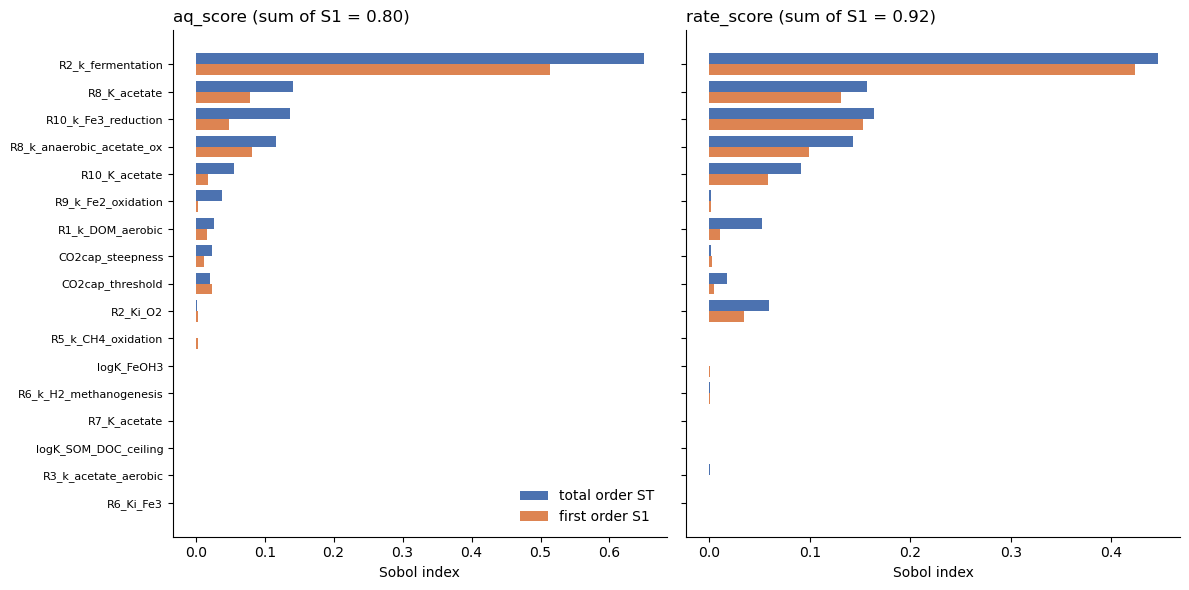

In [4]:
sob = match.sobol_scores(fit, cfg.sobol_n, cfg.seed); names = fit["names"]; order = np.argsort(-sob["aq_score"][1]); y = np.arange(len(names))[::-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
for ax, c in zip(axes, sob):
    S1, ST = sob[c][0], sob[c][1]; ax.barh(y + 0.2, ST[order], height=0.4, color="#4c72b0", label="total order ST"); ax.barh(y - 0.2, S1[order], height=0.4, color="#dd8452", label="first order S1")
    ax.set_title(f"{c} (sum of S1 = {S1.sum():.2f})", loc="left"); ax.set_xlabel("Sobol index"); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_yticks(y); axes[0].set_yticklabels([names[i] for i in order], fontsize=8); axes[0].legend(frameon=False); plt.tight_layout(); plt.show()

## 4. History matching and the Pareto front
Implausibility $I = |z - E[f]| / \sqrt{\mathrm{Var}_{em} + \sigma_{obs}^2}$ per output; a point is **NROY** (not ruled out yet) if the second-largest $I$ is below 3 and few H$^+$ cells are clamped. With these data the NROY region is empty: no parameter set matches all concentrations and all rates at once (the Fe(III)-reduction rate is structurally too low). The Pareto front lists the best trade-offs between the concentration score and the rate score.

NROY: 0.00 %  |  Pareto front: 20 points


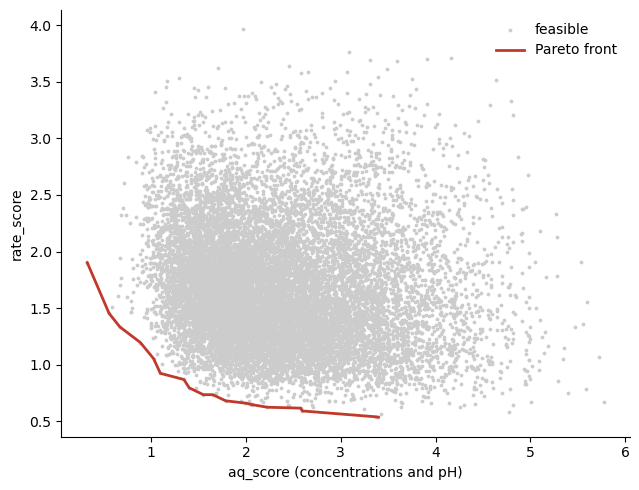

In [5]:
hm = match.history_match(fit, cfg); print(f"NROY: {hm['NROY'].mean() * 100:.2f} %  |  Pareto front: {len(hm['front'])} points")
PA, idx = hm["pred"], np.where(hm["feasible"])[0]
fig, ax = plt.subplots(figsize=(6.5, 5)); ax.scatter(PA[idx, 0], PA[idx, 1], s=3, color="0.8", label="feasible"); f = hm["front"]; ax.plot(PA[f, 0], PA[f, 1], color="#c0392b", lw=2, label="Pareto front")
ax.set_xlabel("aq_score (concentrations and pH)"); ax.set_ylabel("rate_score"); ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

## 5. Candidates for verification
`match.pick_candidates` spreads six points along the Pareto front. The shipped `candidates.csv` holds the six that were verified with 6-year full-model runs (`arctic-sa verify`). The emulator was accurate for the rate score but optimistic for the concentration score, so the verification runs, not the emulator, decide.

In [6]:
display(D("candidates")[LHS_PARAMETERS].T.style.format("{:.3g}"))

member,cand1,cand2,cand3,cand4,cand5,cand6
R1_k_DOM_aerobic,1.48e-07,3.33e-10,1.02e-09,2.12e-09,1.24e-09,1.07e-09
R2_k_fermentation,1.69e-09,6.44e-12,2.78e-11,1.58e-11,2.25e-11,4.02e-11
R3_k_acetate_aerobic,4.43e-05,2.29e-06,5.29e-07,8.77e-05,3.56e-06,4.59e-05
R5_k_CH4_oxidation,1.21e-10,5.99e-10,1.21e-09,2e-10,2.4e-09,5.25e-12
R6_k_H2_methanogenesis,1.68e-08,9.53e-09,1.6e-07,1.34e-08,7.34e-10,2.89e-10
R8_k_anaerobic_acetate_ox,9.17e-05,3.64e-05,2.85e-05,1.14e-05,1.72e-06,7.51e-07
R9_k_Fe2_oxidation,2.56e-07,1.38e-07,1.31e-08,3.69e-06,1.15e-06,2.2e-06
R10_k_Fe3_reduction,2.9e-07,1.66e-06,1.42e-06,7.23e-06,3.76e-06,2.08e-06
R10_K_acetate,0.0866,0.00449,0.0365,0.00726,0.00844,0.0043
R8_K_acetate,0.000368,0.0132,0.0133,0.00914,0.00142,0.000191
